# 01 · Preprocessing — Gulati 2020 Breast Cancer (malignant compartment)

Isolate malignant cells, threshold thin samples by a **data-driven multiplicative gap**,
integrate patients (Harmony), embed, remove detached islands, and characterise the
manifold's transcriptional compartments. Gulati et al. profiled breast tumours by
**SmartSeq2** (deep, full-length; log1p-TPM), so per-cell scores are far less
dropout-dominated than the 10x reference runs. Every tunable choice is **derived from
this dataset**, not inherited from the Puram anchor. Deliverable: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>-1
name = os.path.basename(os.getcwd())                    # e.g. Gulati2020_Breast-1
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition (Breast)
raw_name = 'Data_' + name.rsplit('-1', 1)[0]            # raw input strips the -1 run suffix
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', raw_name)                              # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)    # h5ads
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| raw:', raw_name)

dataset: Gulati2020_Breast-1 | category: Breast | raw: Data_Gulati2020_Breast


### Load malignant compartment
Gulati et al. annotate cell type directly; we take their `Malignant` calls (tumour
epithelial). Expression is SmartSeq2 TPM, `log1p`-transformed by the loader.

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p TPM, full-length SmartSeq2)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Gulati2020_Breast
Done.
full atlas: (1902, 42132)
malignant: (861, 42132) | samples: 8
expression: X max 12.42 (log1p TPM, full-length SmartSeq2)


### Sample thresholding — derived by multiplicative gap-finding
Per-sample malignant counts span a factor of ~4. Rather than a round-number cut, we find
the largest **multiplicative** cliff in the sorted counts and cut at its geometric mean —
the natural separatrix between well-sampled tumours and thin samples. (C1/C2: the rule is
computed and shown here, not inherited from Puram's fixed ≥100.)

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', n.values.tolist())
print(f'largest multiplicative gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')

sorted per-sample counts: [191, 150, 139, 107, 83, 80, 68, 43]
largest multiplicative gap: 68 -> 43 (ratio 1.58)
derived threshold (geometric mean across the gap) = 54
kept 7/8 samples -> 818 cells


### Overdispersion, PCA, Harmony integration, embedding
`theta` is selected by a per-cell **iLISI** sweep (integration LISI on `sample`; higher =
better mixing, max = #samples). We take the smallest theta past which mixing plateaus. PC
count is read off the scree plateau (elbow at PC2–3 under-powers a continuous manifold —
the Chen 2020 lesson); UMAP spread 1.3 follows the reference runs.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
print('PCA variance ratio, PC1-8:', np.round(vr[:8], 4).tolist())
print('scree flattens by ~PC20 (var ratio < 0.01, no sharp elbow) -> n_pcs=20 (robust plateau)')

# theta sweep on per-cell iLISI (integration LISI on sample; higher = better mixing)
def ilisi(rep, labels, k=30):
    nn = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    lab = pd.Categorical(labels).codes; out = []
    for i in range(len(lab)):
        _, c = np.unique(lab[nn[i]], return_counts=True); p = c/c.sum(); out.append(1/np.sum(p**2))
    return np.array(out)

samp = adata.obs['sample'].values; nsamp = len(keep)
base = ilisi(adata.obsm['X_pca'][:,:20], samp)
print(f'pre-Harmony iLISI median {np.median(base):.2f} (max = {nsamp} samples)')
sweep = {}
for th in [1, 2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    il = ilisi(adata.obsm['X_pca_harmony'][:,:20], samp)
    sweep[th] = (np.median(il), (il>2).mean())
    print(f'theta={th:2d}: iLISI median {np.median(il):.2f} | frac cells iLISI>2 = {(il>2).mean():.2f}')
theta = 2
print(f'selected theta = {theta} (iLISI plateaus by theta=2; all cells well-mixed, iLISI>2)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 168 over-dispersed features (0:00:00) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 168
PCA variance ratio, PC1-8: [0.1574, 0.0801, 0.0363, 0.0213, 0.0187, 0.0164, 0.0132, 0.0123]
scree flattens by ~PC20 (var ratio < 0.01, no sharp elbow) -> n_pcs=20 (robust plateau)
pre-Harmony iLISI median 2.47 (max = 7 samples)
theta= 1: iLISI median 4.57 | frac cells iLISI>2 = 1.00
theta= 2: iLISI median 4.79 | frac cells iLISI>2 = 1.00
theta= 5: iLISI median 4.95 | frac cells iLISI>2 = 1.00
theta=10: iLISI median 5.06 | frac cells iLISI>2 = 1.00
selected theta = 2 (iLISI plateaus by theta=2; all cells well-mixed, iLISI>2)


### Cell-cycle phase (for the compartment biology check)
SmartSeq2 depth resolves cycling cleanly; phase is scored from the canonical Tirosh
S / G2M gene sets. This is used below to test whether any compartment split is driven by
proliferation (the Kürten confound) or is orthogonal to the developmental axis.

In [6]:
s_genes = ['MCM5','PCNA','TYMS','FEN1','MCM2','MCM4','RRM1','UNG','GINS2','MCM6','CDCA7','DTL','PRIM1','UHRF1','MLF1IP','HELLS','RFC2','RPA2','NASP','RRM2','CDC45','CDC6','EXO1','TIPIN','DSCC1','BLM','CASP8AP2','USP1','CLSPN','POLA1','CHAF1B','BRIP1','E2F8']
g2m_genes = ['HMGB2','CDK1','NUSAP1','UBE2C','BIRC5','TPX2','TOP2A','NDC80','CKS2','NUF2','CKS1B','MKI67','TMPO','CENPF','TACC3','FAM64A','SMC4','CCNB2','CKAP2L','CKAP2','AURKB','BUB1','KIF11','ANP32E','TUBB4B','GTSE1','KIF20B','HJURP','CDCA3','HN1','CDC20','TTK','CDC25C','KIF2C','RANGAP1','NCAPD2','DLGAP5','CDCA2','CDCA8','ECT2','KIF23','HMMR','AURKA','PSRC1','ANLN','LBR','CKAP5','CENPE','CTCF','NEK2','G2E3','GAS2L3','CBX5','CENPA']
sc.tl.score_genes_cell_cycle(adata, s_genes=[g for g in s_genes if g in adata.var_names],
                             g2m_genes=[g for g in g2m_genes if g in adata.var_names])
adata.obs['cell_cycle_phase'] = adata.obs['phase']
adata.obs['cycling'] = adata.obs['phase'].isin(['S','G2M'])
print('cell-cycle phase:', adata.obs['phase'].value_counts().to_dict())

cell-cycle phase: {'G2M': 345, 'G1': 267, 'S': 206}


### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6× the median nearest-neighbour distance) and drop any
cell outside the main connected component — stripping physically detached specks while
keeping the continuous manifold body.

In [7]:
um = adata.obsm['X_umap']
d, _ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('detached islands:', ncomp-1, '| cells removed:', int((lab!=main).sum()))
adata = adata[lab==main].copy()
print('manifold is a single connected component:', adata.shape[0], 'cells')

detached islands: 0 | cells removed: 0
manifold is a single connected component: 818 cells


### Compartment split + biology check (data-driven)
Low-resolution Leiden (res=0.15) recovers the manifold's lobes. We label them *by biology*:
the compartment with the **lower cycling fraction** is the **low-cycling** candidate, the
other **high-cycling**. Crucially, we test whether this split is confounded with the
developmental modules — if module means are near-identical across lobes and each module
correlates ~0 with the cycling fraction, the proliferation split is **orthogonal** to the
developmental axis and no lobe scoping is warranted (the Bischoff/Sun/Lee precedent), unlike
Kürten where the cycling lobe had to be excluded. The scope decision is finalised in 02.

In [8]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
lo_lobe = cyc.idxmin()
lab_map = {l: ('Low-cycling' if l==lo_lobe else 'High-cycling') for l in adata.obs['lobe'].cat.categories}
adata.obs['compartment'] = adata.obs['lobe'].map(lab_map).astype('category')
print('lobe sizes:', adata.obs['lobe'].value_counts().sort_index().to_dict())
print('cycling fraction per lobe:', cyc.round(3).to_dict())
print('compartments:', adata.obs['compartment'].value_counts().to_dict())

lobe sizes: {'0': 513, '1': 305}
cycling fraction per lobe: {'0': 0.602, '1': 0.793}
compartments: {'Low-cycling': 513, 'High-cycling': 305}


### Publication subtypes (annotation uses data + original publication)
Gulati et al. report three malignant cell-subtypes (Basal, Luminal progenitor, Mature
luminal). We carry their calls as `cell_subtype` for annotation context — the developmental
trajectory in 02 is scored independently of these labels.

In [9]:
print('publication subtype x compartment:')
print(pd.crosstab(adata.obs['compartment'], adata.obs['cell_subtype']).to_string())

publication subtype x compartment:
cell_subtype  Basal  Luminal progenitor  Mature luminal
compartment                                            
Low-cycling     270                 152              91
High-cycling      3                  51             251


### Gate 1 — batch mixing & manifold continuity
Samples must intermix (no per-patient islands) on one continuous manifold. The read is made
on the **regenerated embedding itself** across the integration (theta) + n_pcs sweep above,
with the per-cell iLISI metric — never a single scalar. Here: pre-Harmony iLISI already
2.5/7, rising to ~4.8 with all cells iLISI>2 by theta=2; a single connected component; and
(below) the samples are visibly intermixed across the whole manifold. **Gate 1 = GO.**

7 samples share one continuous manifold; iLISI median 4.79/7 at theta=2, 100% of cells iLISI>2.
Gate 1: samples intermixed on one continuous manifold -> GO


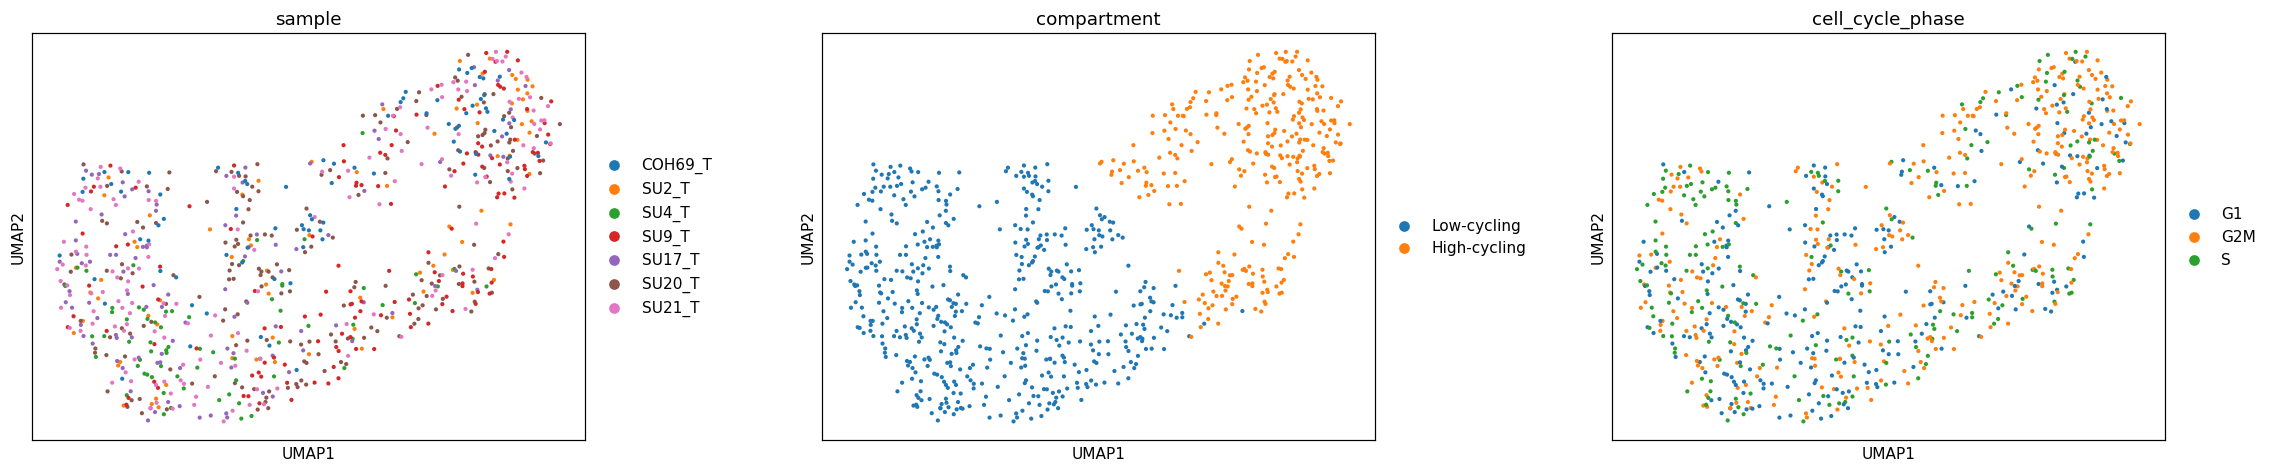

In [10]:
fig = sc.pl.umap(adata, color=['sample','compartment','cell_cycle_phase'],
                 size=30, wspace=.3, show=False)
print(f"{adata.obs['sample'].nunique()} samples share one continuous manifold; "
      f"iLISI median {sweep[2][0]:.2f}/{len(keep)} at theta=2, {sweep[2][1]*100:.0f}% of cells iLISI>2.")
print('Gate 1: samples intermixed on one continuous manifold -> GO')

### Save processed data

In [11]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (818, 28226)


### Sample-integration figure (deliverable)
House style: `figsize=(3.5,1.5)` horizontal strip, `size=30`, colour = sample. Intermixing
across the strip is the Gate-1 batch-integration evidence. Orientation is set so the
trajectory (derived in 02) reads left→right; direction is immaterial for this categorical
panel, so here we show the raw embedding.

saved samples.pdf | cells: 818


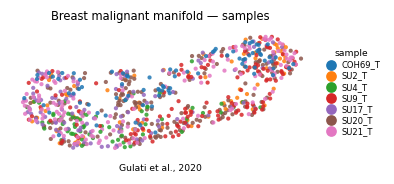

In [12]:
plot = adata.copy()
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.85, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('Breast malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Gulati et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])